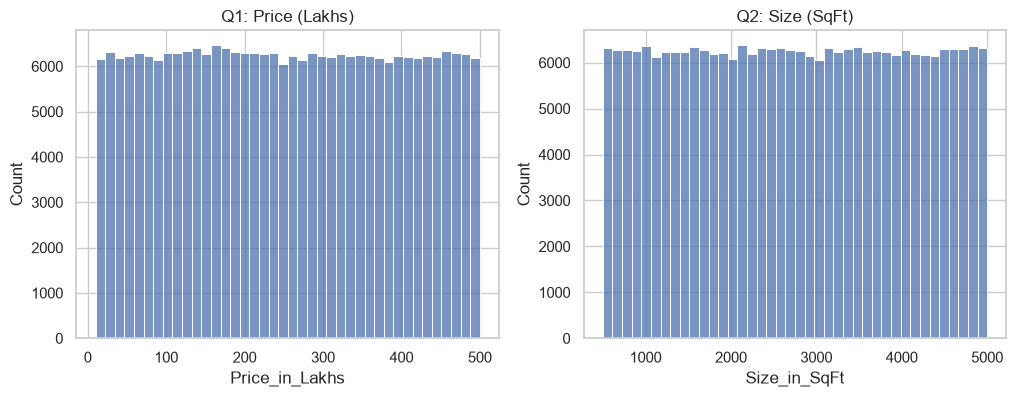

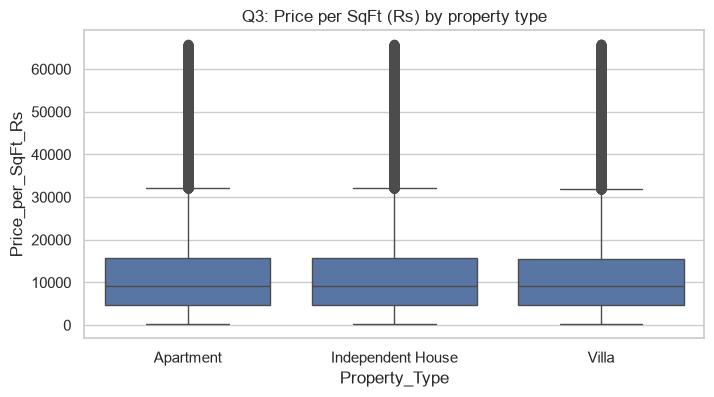

                      mean  median
Property_Type                     
Apartment          13047.0  9245.0
Independent House  13102.0  9305.0
Villa              13026.0  9190.0


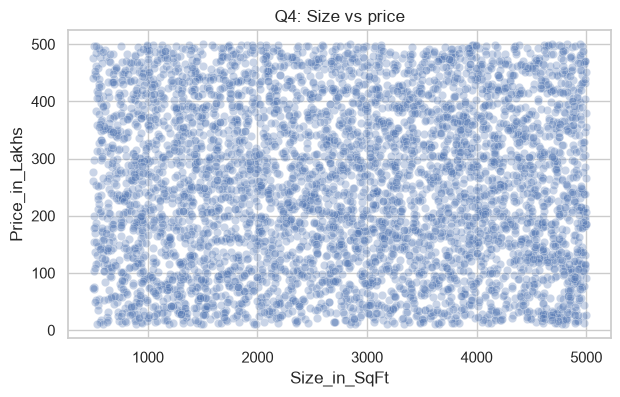

Correlation (size, price): -0.003


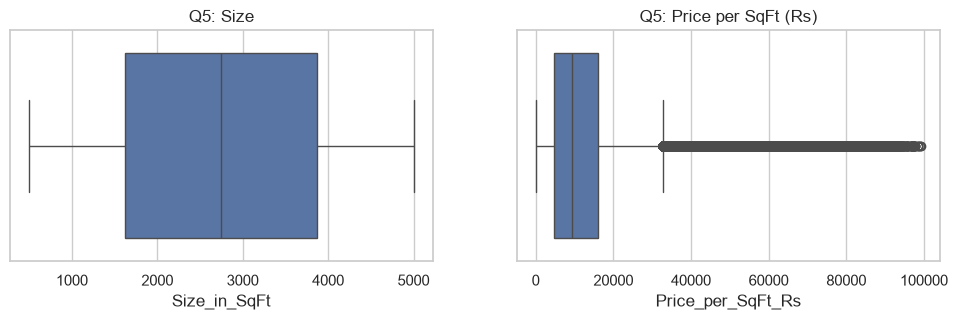

In [6]:
# Q1 and Q2: distributions
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price_in_Lakhs"], bins=40, ax=ax[0]); ax[0].set_title("Q1: Price (Lakhs)")
sns.histplot(df["Size_in_SqFt"], bins=40, ax=ax[1]); ax[1].set_title("Q2: Size (SqFt)")
plt.show()

# Q3: price per sq ft by property type (clipped at the 99th percentile for readability)
cap = df["Price_per_SqFt_Rs"].quantile(0.99)
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[df["Price_per_SqFt_Rs"] <= cap], x="Property_Type", y="Price_per_SqFt_Rs")
plt.title("Q3: Price per SqFt (Rs) by property type")
plt.show()
print(df.groupby("Property_Type")["Price_per_SqFt_Rs"].agg(["mean", "median"]).round(0))

# Q4: size vs price (5,000-row sample, since 250k points make an unreadable cloud)
sample = df.sample(5000, random_state=42)
plt.figure(figsize=(7, 4))
sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.3)
plt.title("Q4: Size vs price")
plt.show()
print("Correlation (size, price):", round(df["Size_in_SqFt"].corr(df["Price_in_Lakhs"]), 3))

# Q5: outliers
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=df["Size_in_SqFt"], ax=ax[0]); ax[0].set_title("Q5: Size")
sns.boxplot(x=df["Price_per_SqFt_Rs"], ax=ax[1]); ax[1].set_title("Q5: Price per SqFt (Rs)")
plt.show()

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/processed/housing_clean.csv")
df.shape

(250000, 29)

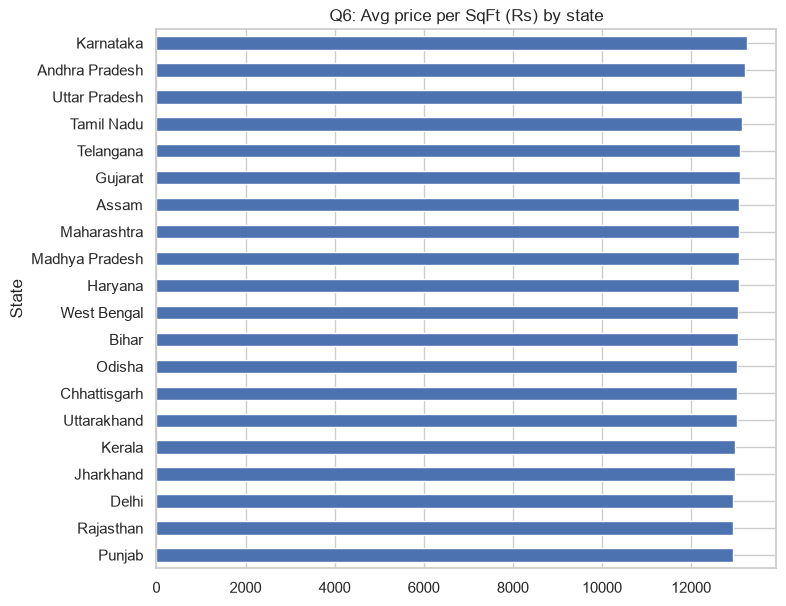

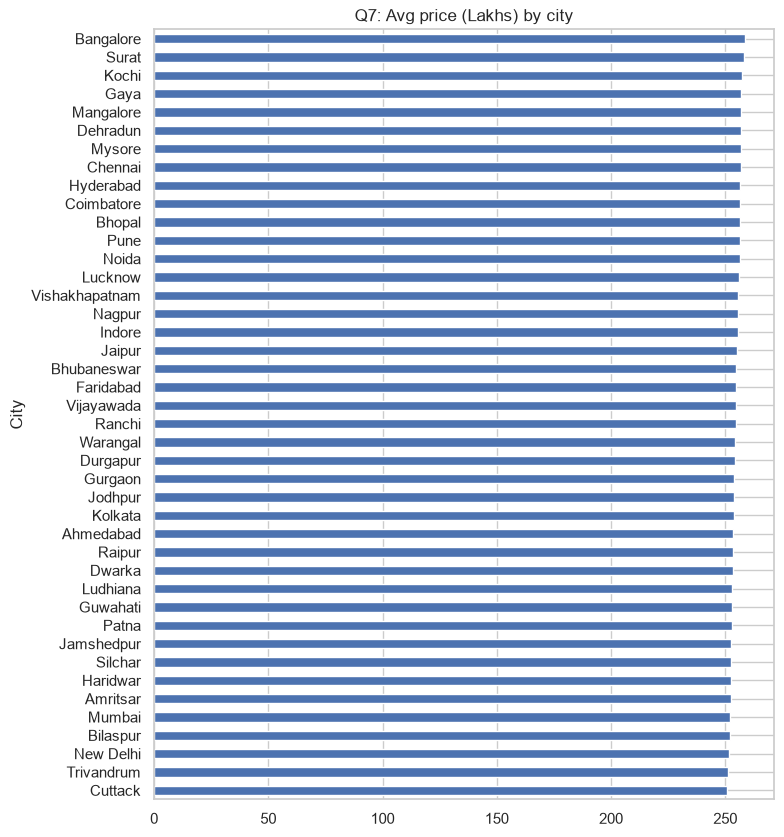

Oldest localities:
 Locality
Locality_499    20.0
Locality_99     20.0
Locality_127    20.0
Locality_403    21.0
Locality_72     21.0
Name: Age_of_Property, dtype: float64 

Newest localities:
 Locality
Locality_443    16.0
Locality_92     17.0
Locality_60     17.0
Locality_10     17.0
Locality_13     17.0
Name: Age_of_Property, dtype: float64

Spread of medians:
 count    500.0
mean      18.5
std        0.8
min       16.0
25%       18.0
50%       18.0
75%       19.0
max       21.0
Name: Age_of_Property, dtype: float64


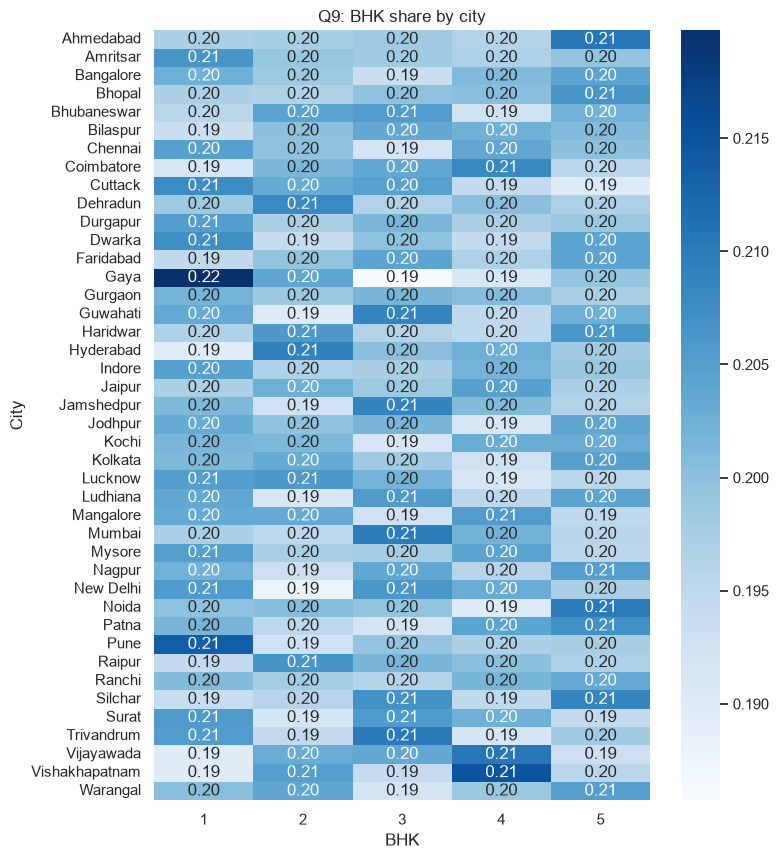

Cities per locality name:
 count    500.0
mean      42.0
std        0.0
min       41.0
25%       42.0
50%       42.0
75%       42.0
max       42.0
Name: City, dtype: float64


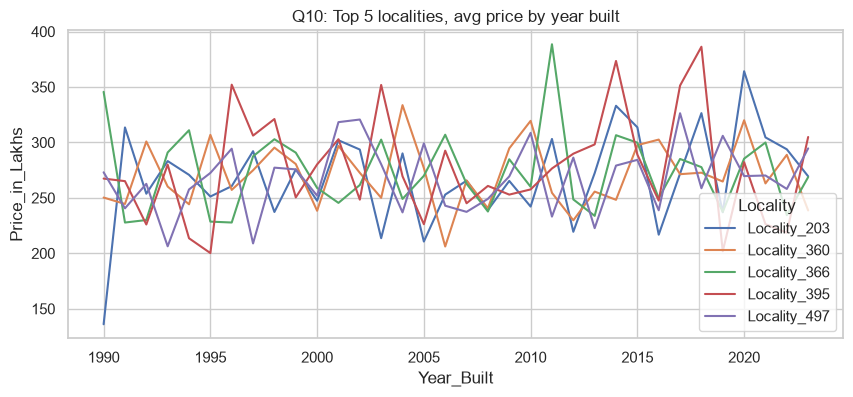

In [ ]:
# Q6: average price per sq ft by state
df.groupby("State")["Price_per_SqFt_Rs"].mean().sort_values().plot(
    kind="barh", figsize=(8, 7), title="Q6: Avg price per SqFt (Rs) by state")
plt.show()

# Q7: average price by city
df.groupby("City")["Price_in_Lakhs"].mean().sort_values().plot(
    kind="barh", figsize=(8, 10), title="Q7: Avg price (Lakhs) by city")
plt.show()

# Q8: median age by locality (there are hundreds, so summarise)
loc_age = df.groupby("Locality")["Age_of_Property"].median().sort_values()
print("Oldest localities:\n", loc_age.tail(5), "\n\nNewest localities:\n", loc_age.head(5))
print("\nSpread of medians:\n", loc_age.describe().round(1))

# Q9: BHK distribution by city (share of each BHK within a city)
plt.figure(figsize=(8, 10))
sns.heatmap(pd.crosstab(df["City"], df["BHK"], normalize="index"),
            annot=True, fmt=".2f", cmap="Blues")
plt.title("Q9: BHK share by city")
plt.show()

# Q10: top 5 most expensive localities, trend by year built
# (the data has no sale dates, so Year_Built is our time axis)
print("Cities per locality name:\n", df.groupby("Locality")["City"].nunique().describe().round(1))
top5 = df.groupby("Locality")["Price_in_Lakhs"].mean().nlargest(5).index
trend = (df[df["Locality"].isin(top5)]
         .groupby(["Year_Built", "Locality"])["Price_in_Lakhs"].mean().reset_index())
plt.figure(figsize=(10, 4))
sns.lineplot(data=trend, x="Year_Built", y="Price_in_Lakhs", hue="Locality")
plt.title("Q10: Top 5 localities, avg price by year built")
plt.show()


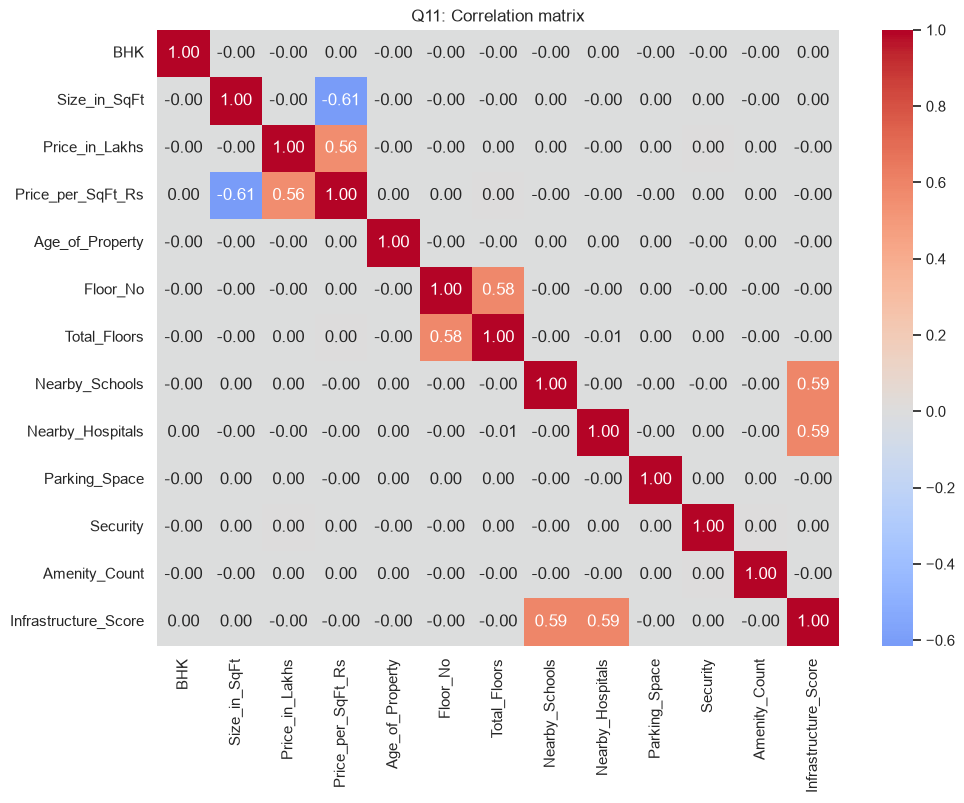

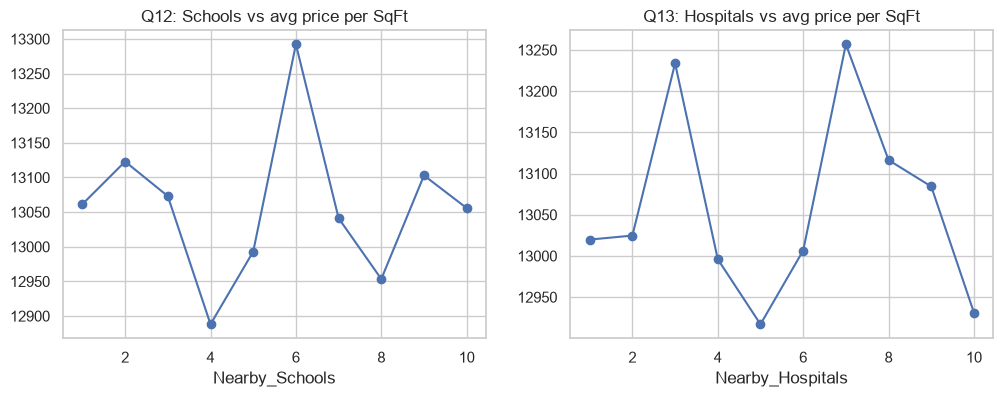

Q14: by furnished status
                  Price_in_Lakhs  Price_per_SqFt_Rs
Furnished_Status                                   
Furnished                  254.4            13033.8
Semi-furnished             254.3            13093.1
Unfurnished                255.0            13047.9

Q15: by facing
           mean  median
Facing                 
East    13024.0  9234.0
North   13025.0  9219.0
South   13044.0  9225.0
West    13140.0  9308.0


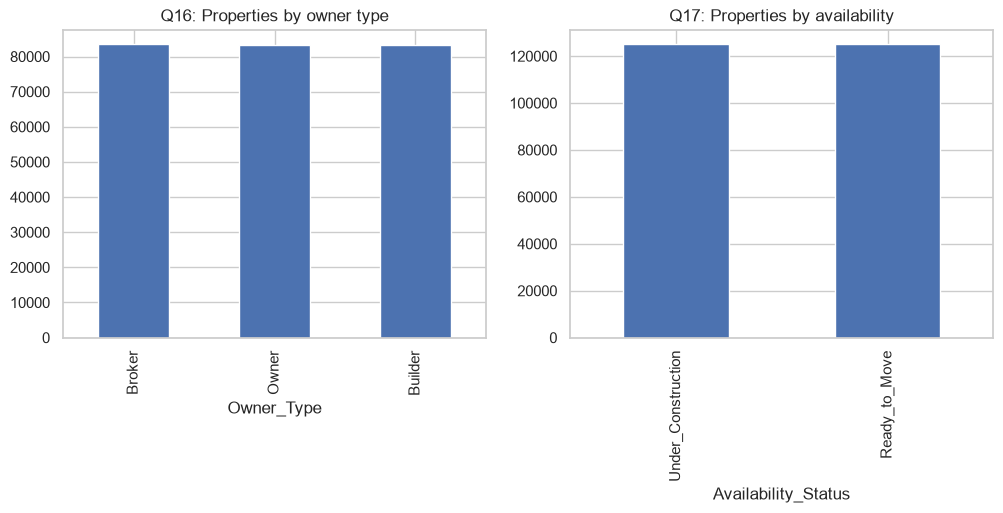

Q18: parking vs price
               Price_in_Lakhs  Price_per_SqFt_Rs
Parking_Space                                   
0                       254.4            13071.8
1                       254.7            13044.7

Q19: amenity count vs price per sq ft
Amenity_Count
1    13015.0
2    13059.0
3    13044.0
4    13071.0
5    13102.0
Name: Price_per_SqFt_Rs, dtype: float64

Q20: transport accessibility
                                 avg_ppsf  good_investment_rate
Public_Transport_Accessibility                                 
High                            13027.242                 0.470
Low                             13085.539                 0.234
Medium                          13062.233                 0.367


In [9]:
# Q11: correlation heatmap
num_cols = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt_Rs", "Age_of_Property",
            "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals",
            "Parking_Space", "Security", "Amenity_Count", "Infrastructure_Score"]
plt.figure(figsize=(11, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Q11: Correlation matrix")
plt.show()

# Q12 and Q13: schools and hospitals vs price per sq ft
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("Nearby_Schools")["Price_per_SqFt_Rs"].mean().plot(marker="o", ax=ax[0], title="Q12: Schools vs avg price per SqFt")
df.groupby("Nearby_Hospitals")["Price_per_SqFt_Rs"].mean().plot(marker="o", ax=ax[1], title="Q13: Hospitals vs avg price per SqFt")
plt.show()

# Q14 and Q15: furnished status and facing
print("Q14: by furnished status")
print(df.groupby("Furnished_Status")[["Price_in_Lakhs", "Price_per_SqFt_Rs"]].mean().round(1))
print("\nQ15: by facing")
print(df.groupby("Facing")["Price_per_SqFt_Rs"].agg(["mean", "median"]).round(0))

# Q16 and Q17: counts
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["Owner_Type"].value_counts().plot(kind="bar", ax=ax[0], title="Q16: Properties by owner type")
df["Availability_Status"].value_counts().plot(kind="bar", ax=ax[1], title="Q17: Properties by availability")
plt.show()

# Q18: parking
print("Q18: parking vs price")
print(df.groupby("Parking_Space")[["Price_in_Lakhs", "Price_per_SqFt_Rs"]].mean().round(1))

# Q19: amenity count
print("\nQ19: amenity count vs price per sq ft")
print(df.groupby("Amenity_Count")["Price_per_SqFt_Rs"].mean().round(0))

# Q20: transport vs price per sq ft and investment rate
print("\nQ20: transport accessibility")
print(df.groupby("Public_Transport_Accessibility").agg(
    avg_ppsf=("Price_per_SqFt_Rs", "mean"),
    good_investment_rate=("Good_Investment", "mean")).round(3))